In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

/tmp/ipykernel_2496201/731869154.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([pretty_model.get(m, m) for m in model_order], fontsize=10)


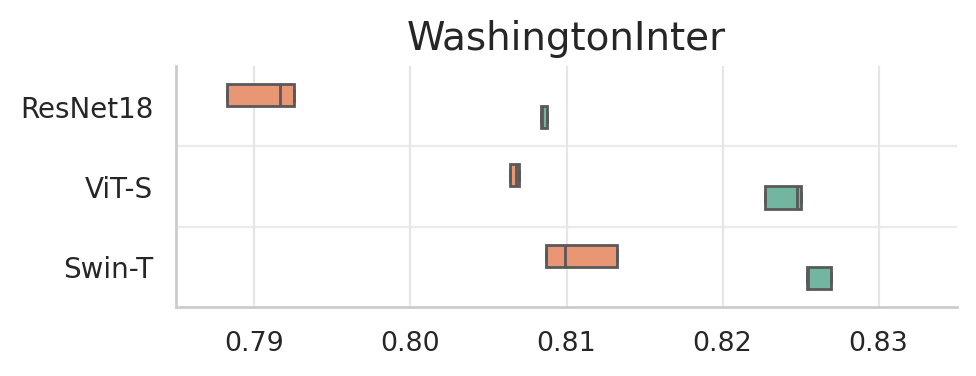

In [90]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]

metric = "iou"
model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {
    "resnet18": "ResNet18",
    "vit_small": "ViT-S",
    "swin_tiny": "Swin-T",
}

# --- style tuned for papers ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlepad": 6,
    "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(5, 2))  # compact for 1-column paper

# stable palette across figures
tags = list(results["tag"].unique())
palette = dict(zip(tags, sns.color_palette("colorblind", n_colors=len(tags))))

# --- choose ONE palette ---
# palette_list = sns.color_palette("Dark2", n_colors=len(tags))          # recommended for 2–4 tags
# palette_list = sns.color_palette("deep", n_colors=len(tags))
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

sns.boxplot(
    data=results,
    y="model", x=metric, hue="tag",
    order=model_order,
    palette=palette,
    width=0.55,
    linewidth=1.0,
    whis=(5, 95),          # more robust whiskers than default 1.5 IQR
    showfliers=False,
    ax=ax,
    legend=False
)

# subtle separators (lighter than your current)
for y in range(1, len(model_order)):
    ax.axhline(y - 0.5, color="0.92", linewidth=0.8, zorder=0)

ax.set_title("WashingtonInter", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")  # cleaner; model names already on axis
ax.set_yticklabels([pretty_model.get(m, m) for m in model_order], fontsize=10)

# lighter grid, only on x (since x is numeric)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="0.9", linewidth=0.8)

# optional: consistent x-range for IoU
ax.set_xlim(0.785, 0.835)

fig.tight_layout()
plt.savefig("visualizations/washingtoninter_iou.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
plt.show()

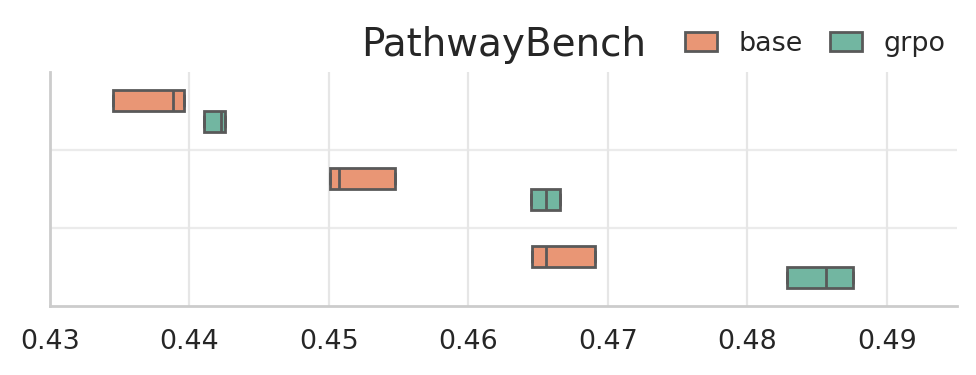

In [88]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]

metric = "iou"
model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {
    "resnet18": "ResNet18",
    "vit_small": "ViT-S",
    "swin_tiny": "Swin-T",
}

# --- style tuned for papers ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlepad": 6,
    "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(5, 2))  # compact for 1-column paper

# stable palette across figures
tags = list(results["tag"].unique())
palette = dict(zip(tags, sns.color_palette("colorblind", n_colors=len(tags))))

# --- choose ONE palette ---
# palette_list = sns.color_palette("Dark2", n_colors=len(tags))          # recommended for 2–4 tags
# palette_list = sns.color_palette("deep", n_colors=len(tags))
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

sns.boxplot(
    data=results,
    y="model", x=metric, hue="tag",
    order=model_order,
    palette=palette,
    width=0.55,
    linewidth=1.0,
    whis=(5, 95),          # more robust whiskers than default 1.5 IQR
    showfliers=False,
    ax=ax
)

# subtle separators (lighter than your current)
for y in range(1, len(model_order)):
    ax.axhline(y - 0.5, color="0.92", linewidth=0.8, zorder=0)

ax.set_title("PathwayBench", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")  # cleaner; model names already on axis
ax.set_yticklabels("")

# legend on top/right, compact
leg = ax.legend(
    title="",
    loc="lower right",
    bbox_to_anchor=(1.0, 1.02),
    ncol=len(tags),
    borderaxespad=0.0,
    handlelength=1.2,
    columnspacing=1.0
)

# lighter grid, only on x (since x is numeric)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="0.9", linewidth=0.8)

# optional: consistent x-range for IoU
ax.set_xlim(0.43, 0.495)

fig.tight_layout()
plt.savefig("visualizations/pathwaybench_iou.png", bbox_inches="tight", pad_inches=0.0, dpi=600)
plt.show()

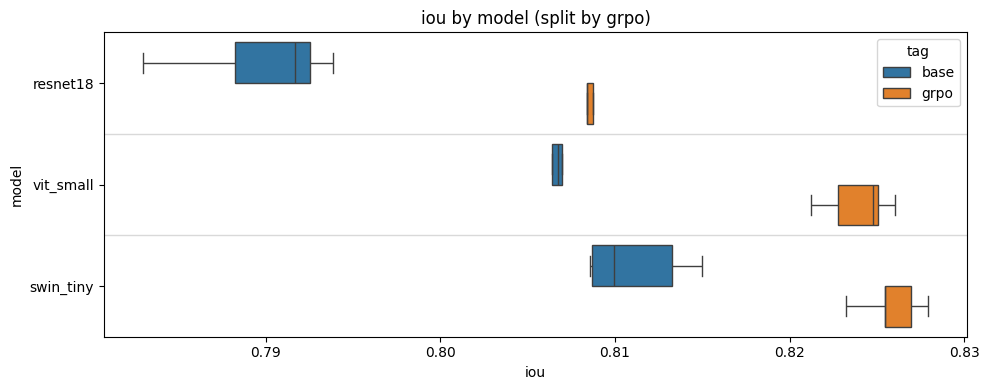

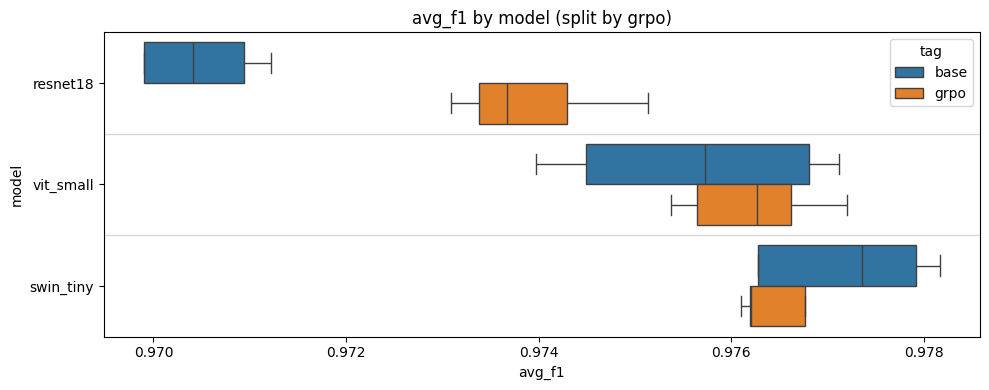

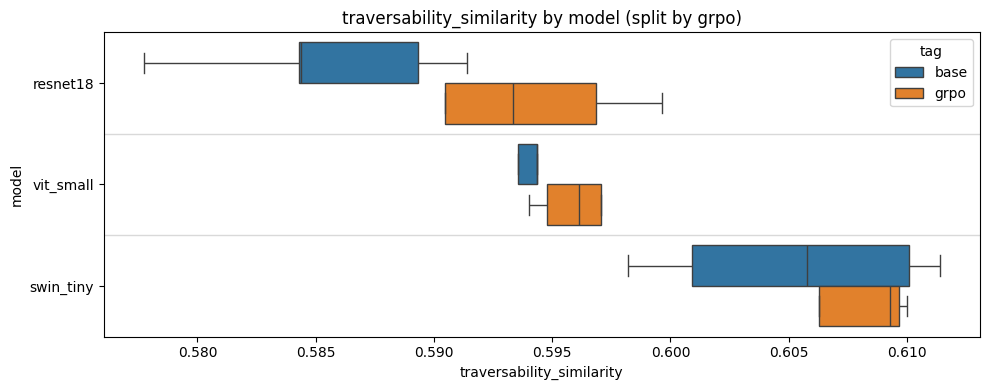

In [3]:
for metric in ["iou", "avg_f1", "traversability_similarity"]:
    plt.figure(figsize=(10, 4))
    model_order = ["resnet18", "vit_small", "swin_tiny"]
    ax = sns.boxplot(
        y="model", x=metric, hue="tag",
        data=results,
        order=model_order,
        showbox=True,
        showfliers=False
    )
    n_models = results["model"].nunique()
    for y in range(1, n_models):
        ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
    ax.set_title(f"{metric} by model (split by grpo)")
    plt.tight_layout()
    plt.show()

In [4]:
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.789849,0.969799,0.585430
1,resnet18,grpo,0.808222,0.973909,0.591714
2,swin_tiny,base,0.811085,0.976623,0.605276
3,swin_tiny,grpo,0.825803,0.976729,0.606924
4,vit_small,base,0.807622,0.975621,0.593477
5,vit_small,grpo,0.823953,0.976221,0.596924


In [5]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.004366,0.001897,0.005310
1,resnet18,grpo,0.001685,0.000815,0.008263
2,swin_tiny,base,0.002889,0.001939,0.005698
3,swin_tiny,grpo,0.001777,0.000960,0.004472
4,vit_small,base,0.003051,0.001383,0.005166
5,vit_small,grpo,0.001943,0.000737,0.003386


### PathwayBench

In [2]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]

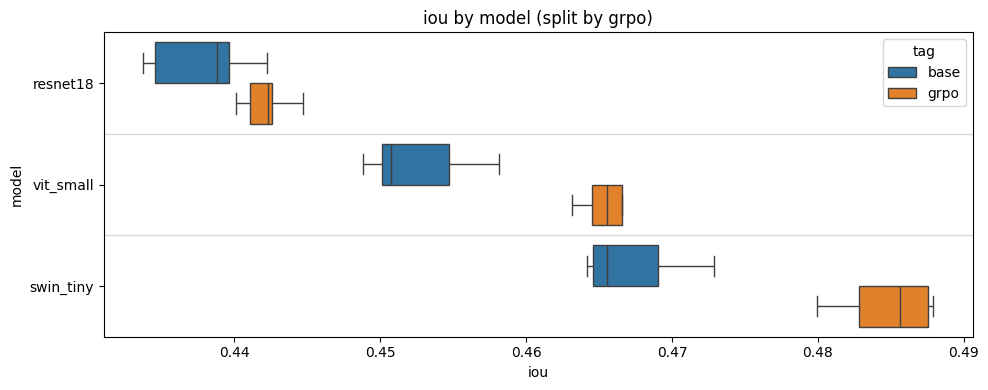

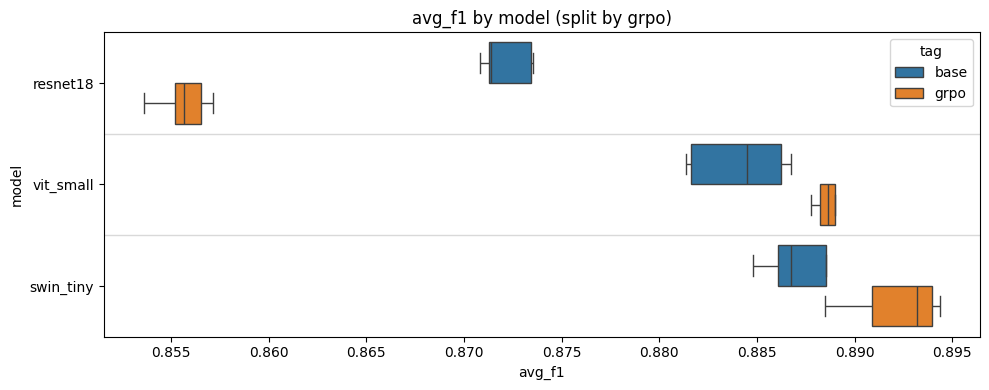

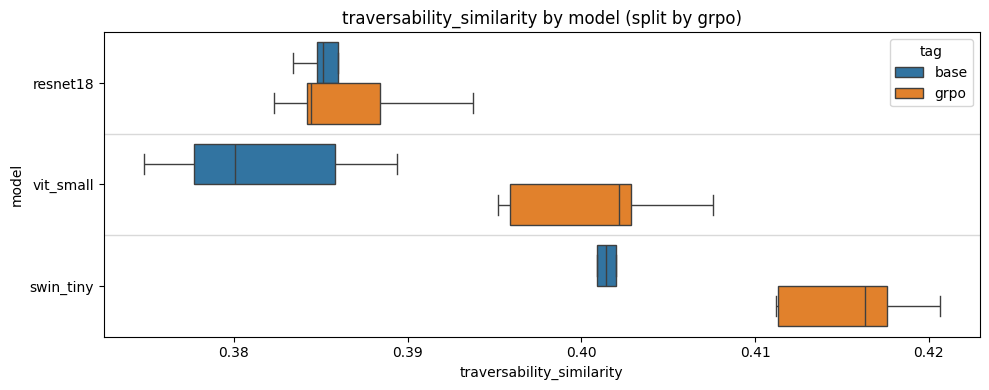

In [7]:
for metric in ["iou", "avg_f1", "traversability_similarity"]:
    plt.figure(figsize=(10, 4))
    model_order = ["resnet18", "vit_small", "swin_tiny"]
    ax = sns.boxplot(
        y="model", x=metric, hue="tag",
        data=results,
        order=model_order,
        showbox=True,
        showfliers=False
    )
    n_models = results["model"].nunique()
    for y in range(1, n_models):
        ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
    ax.set_title(f"{metric} by model (split by grpo)")
    plt.tight_layout()
    plt.show()

In [5]:
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.437797,0.872079,0.385890
1,resnet18,grpo,0.442145,0.855619,0.386631
2,swin_tiny,base,0.467256,0.887781,0.400705
3,swin_tiny,grpo,0.484781,0.892170,0.415410
4,vit_small,base,0.452502,0.884082,0.381567
5,vit_small,grpo,0.466169,0.888916,0.400737


In [8]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.003582,0.001293,0.002542
1,resnet18,grpo,0.001738,0.001365,0.004549
2,swin_tiny,base,0.003683,0.003100,0.003559
3,swin_tiny,grpo,0.003368,0.002471,0.004109
4,vit_small,base,0.003849,0.002508,0.005967
5,vit_small,grpo,0.003027,0.001241,0.005180
